In [2]:
import json, random, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch

DATA_ROOT = Path("../data")   # train.csv, val.csv, test.csv, images/, kart json'u burada olmalı
card = json.load(open(next(DATA_ROOT.glob("*card*.json"))))   # dataset_card / data_card fark etmez

SEED = card["seed"]
CLASS_NAMES = card["classes"]
NUM_CLASSES = len(CLASS_NAMES)

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| seed:", SEED, "| sınıf sayısı:", NUM_CLASSES)

Device: cuda | seed: 20261019 | sınıf sayısı: 9


Seed’i karttan almak, jürinin aynı sonucu yeniden üretebilmesini sağlar. Kart dosyasını glob ile buluyoruz çünkü adı dataset_card.json ya da data_card.json olabilir.

In [3]:
dfs = []
for s in ["train", "val", "test"]:
    d = pd.read_csv(DATA_ROOT/f"{s}.csv"); d["split"] = s; dfs.append(d)
df = pd.concat(dfs, ignore_index=True)
print(df.columns.tolist()); print(df.head(3))

def pick(cols, cands):
    return next((c for c in cands if c in cols), None)

path_col  = pick(df.columns, ["path","filepath","file_path","image_path","image","filename","file_name","id"])
label_col = pick(df.columns, ["label","y","class","target","class_id","species","category"])
assert path_col and label_col, f"Sütunlar tanınmadı: {df.columns.tolist()}"
print("yol sütunu:", path_col, "| etiket sütunu:", label_col)

IMG_DIR = DATA_ROOT/"images"
def resolve(p):
    p = str(p)
    for c in [Path(p), DATA_ROOT/p, IMG_DIR/p, IMG_DIR/Path(p).name]:
        if c.exists(): return str(c)
    return None
df["path"] = df[path_col].map(resolve)
assert df.path.isna().sum() == 0, f"Bulunamayan görsel: {df.path.isna().sum()}"

# Etiket: sayısalsa olduğu gibi, isimse karttaki sıraya göre
if df[label_col].dtype == object:
    df["y"] = df[label_col].map({c:i for i,c in enumerate(CLASS_NAMES)})
else:
    df["y"] = df[label_col]

# Karttaki sayılarla birebir doğrula
for s, n in card["counts"].items():
    assert (df.split==s).sum() == n, f"{s}: beklenen {n}, bulunan {(df.split==s).sum()}"
for s in ["train", "val"]:
    got = df[df.split==s].y.astype(int).value_counts().to_dict()
    exp = {int(k):v for k,v in card["class_counts"][s].items()}
    assert got == exp, f"{s} sınıf sayıları kartla uyuşmuyor"
print("Kart ile doğrulama OK")
print("Test etiket doluluğu:", df[df.split=="test"].y.notna().mean())

['id', 'path', 'label', 'group_id', 'source_id', 'sha256', 'split']
          id                  path  label    group_id              source_id  \
0  T03_00000  images/T03_00000.jpg    0.0  20160928_0  20160928-140314-0.jpg   
1  T03_00001  images/T03_00001.jpg    0.0  20160928_0  20160928-140337-0.jpg   
2  T03_00002  images/T03_00002.jpg    0.0  20160928_0  20160928-140731-0.jpg   

                                              sha256  split  
0  27027cb6d4a68a298f70c1b650541461d6dc5345cdb3f6...  train  
1  f59b22345665c84dc3efade60b07fef6a3c2b8b559fe5f...  train  
2  3886f6d831cb27a90bdb45f9bde11bcdf7ef3aa5a490d9...  train  
yol sütunu: path | etiket sütunu: label
Kart ile doğrulama OK
Test etiket doluluğu: 0.0


Üç CSV’yi split sütunuyla tek tabloda birleştirir, sonraki bütün analizler bu tek tabloda yürür.
Görsel yollarını gerçek dosyalara çevirir. Bulunamayan görsel 0 olmalı, yoksa eğitimin ortasında değil burada dururuz.
Satır ve sınıf sayılarını karttakilerle karşılaştırır. Bu bir bütünlük testi: yanlış dosya, eksik satır ya da yanlış etiket eşlemesi varsa hemen yakalarız.
Test etiket doluluğu 0.0 çıkarsa test etiketsiz, bu beklenen durum. Etiket doluysa bile test’i ölçüm için kullanmayacağız.

Bunun anlamı şu: test için sadece tahmin üretebiliriz, kendi başımıza skor hesaplayamayız. Jüri tahminlerimizi gizli etiketlerle karşılaştırıp macro-F1'i hesaplayacak. Bu yüzden val tek ölçüm aracımız, tüm kararları (hangi model, kaç epoch, hangi augmentation) val macro-F1'e göre vereceğiz. Test’e eğitim sırasında hiç dokunmayacağız, yalnızca en sonda tahmin dosyasını üreteceğiz.

split             train   val  train_%  val_%
0 Chinee apple      798    46      6.6    1.7
1 Lantana           630   238      5.2    8.9
2 Parkinsonia       580   316      4.8   11.9
3 Parthenium        772   197      6.4    7.4
4 Prickly acacia    814   161      6.7    6.0
5 Rubber vine       667   184      5.5    6.9
6 Siam weed         495   193      4.1    7.3
7 Snake weed        857    50      7.1    1.9
8 Negative         6496  1277     53.6   48.0


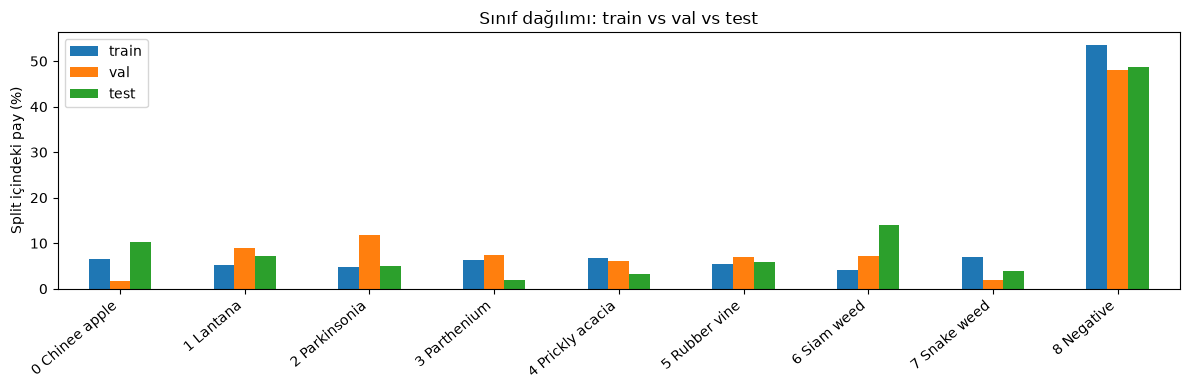

In [4]:
lab = df[df.y.notna()].copy(); lab["y"] = lab.y.astype(int)
ct  = pd.crosstab(lab.y, lab.split)[["train","val"] + (["test"] if (lab.split=="test").any() else [])]
pct = (ct/ct.sum()*100).round(1).add_suffix("_%")
tab = pd.concat([ct, pct], axis=1)
tab.index = [f"{i} {CLASS_NAMES[i]}" for i in tab.index]
print(tab)

# Kartın verdiği test sayılarıyla birlikte, karşılaştırmalı grafik (yüzde)
cc = pd.DataFrame({s: pd.Series({int(k):v for k,v in card["class_counts"][s].items()}) for s in ["train","val","test"]}).sort_index()
(cc/cc.sum()*100).rename(index=lambda i: f"{i} {CLASS_NAMES[i]}").plot.bar(figsize=(12,4))
plt.ylabel("Split içindeki pay (%)"); plt.title("Sınıf dağılımı: train vs val vs test"); plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

Doğrulama geçti, GPU var, sütunlar net. Kartta olmayan ama çok değerli üç sütun var: group_id (çekim günü + kamera, örn. 20160928_0), source_id ve sha256. Bu iki şeyi mümkün kılıyor: gerçek bir sızıntı kontrolü (hash + grup kesişimi) ve ilerleyen günlerde train içinde GroupKFold ile ikinci bir doğrulama kaynağı kurmak. Val’de sınıf 0 (46) ve 7 (50) çok az, bu sınıfların val F1'i gürültülü olacak, küçük farklara fazla anlam yüklemeyeceğiz.

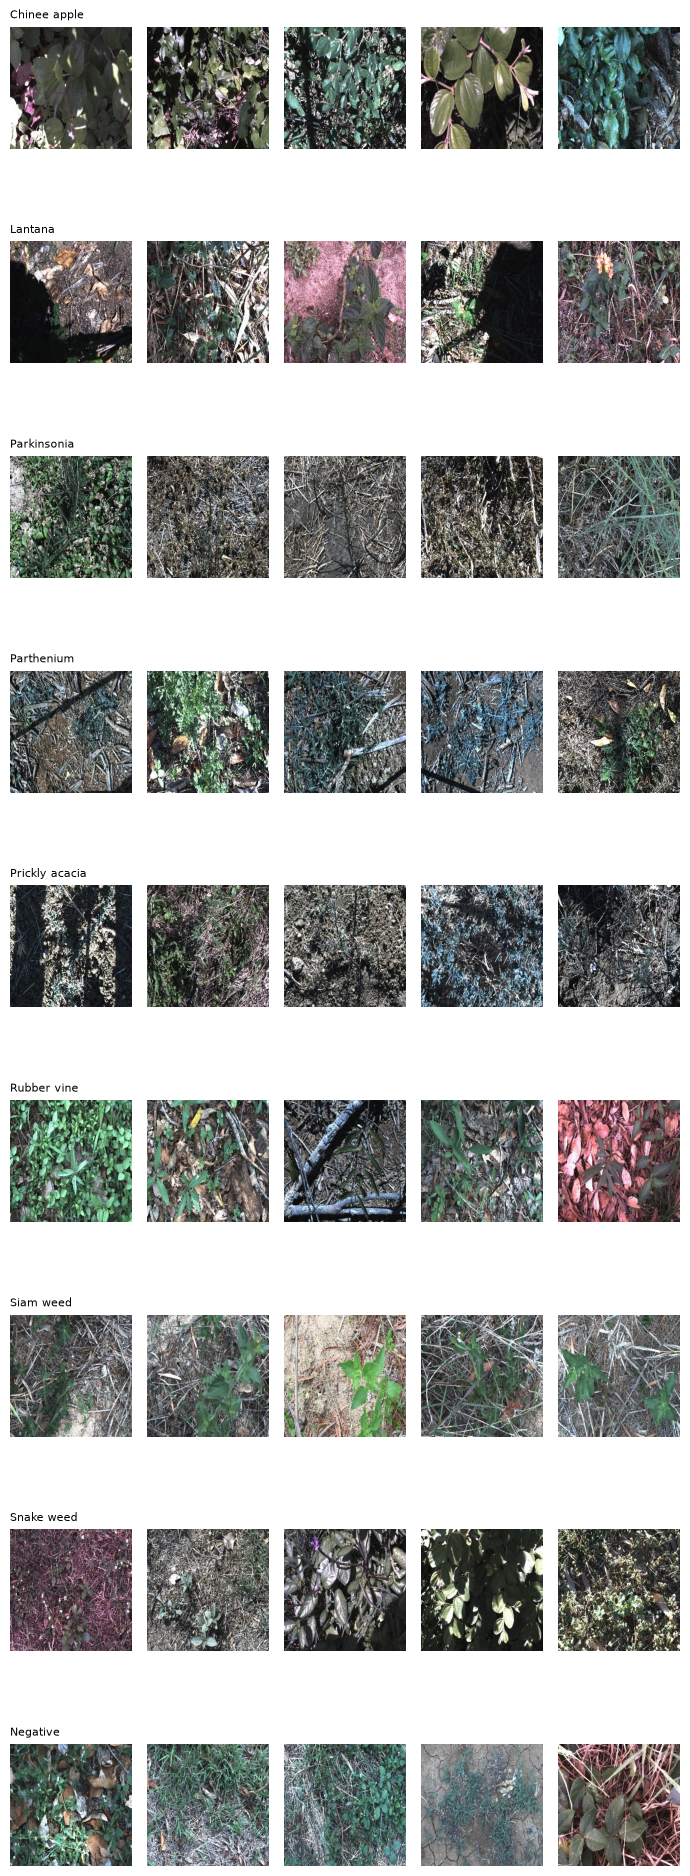

In [5]:
df_l = df[df.split != "test"].copy(); df_l["y"] = df_l.y.astype(int)

def show_samples(n=5):
    fig, axes = plt.subplots(NUM_CLASSES, n, figsize=(1.4*n, 2.2*NUM_CLASSES))
    for i in range(NUM_CLASSES):
        sub = df_l[(df_l.split=="train") & (df_l.y==i)].sample(n, random_state=SEED)
        for j, p in enumerate(sub.path):
            axes[i,j].imshow(Image.open(p)); axes[i,j].axis("off")
        axes[i,0].set_title(CLASS_NAMES[i], fontsize=8, loc="left")
    plt.tight_layout(); plt.show()
show_samples()

Işık, bulanıklık, arka plan çeşitliliğini ve hangi sınıfların birbirine benzediğini görmeden augmentation seçmeyiz. Özellikle “Negative” ile bitki sınıfları arasındaki farkı gözle görmek önemli.

In [6]:
# 1) Birebir kopya: aynı görsel birden fazla split'te var mı?
cross = df.groupby("sha256").split.nunique()
print("Kopya satır:", df.duplicated("sha256", keep=False).sum(),
      "| split'ler arası paylaşılan görsel:", (cross>1).sum())

# 2) Grup (çekim günü + kamera) kesişimi: split'ler gerçekten ayrışmış mı?
gs = {s:set(df[df.split==s].group_id) for s in ["train","val","test"]}
print({s:len(v) for s,v in gs.items()})
print("train∩val:", len(gs["train"]&gs["val"]),
      "| train∩test:", len(gs["train"]&gs["test"]),
      "| val∩test:", len(gs["val"]&gs["test"]))

# 3) Grup başına örnek sayısı ve kamera dağılımı
print(df.groupby(["split","group_id"]).size().groupby("split").describe().round(0))
df["date"] = df.group_id.str.split("_").str[0]
df["cam"]  = df.group_id.str.split("_").str[1]
print(pd.crosstab(df.cam, df.split))

Kopya satır: 0 | split'ler arası paylaşılan görsel: 0
{'train': 68, 'val': 14, 'test': 1}
train∩val: 0 | train∩test: 0 | val∩test: 0
       count   mean    std   min   25%    50%    75%    max
split                                                      
train   68.0  178.0  159.0   5.0  56.0  136.0  258.0  879.0
val     14.0  190.0  160.0  69.0  94.0  174.0  212.0  708.0
split  train   val
cam               
0       1966   152
1       3631   756
2       4399  1012
3       2113   742


Bu sistemin temel amacı, model eğitiminde GPU'nun veri bekleyerek zaman kaybetmesini azaltmak ve veri hazırlama maliyetini düşürmektir.

C:\Users\burak\AppData\Local\Temp\ipykernel_15104\4032133823.py:30: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:209.)
  ytr = torch.from_numpy(tr.y.astype(np.int64).values)


yüklendi: 22s | train (12109, 256, 256, 3) 2.38 GB
batch: (64, 3, 256, 256) torch.float32 | mean=-0.350 std=0.995


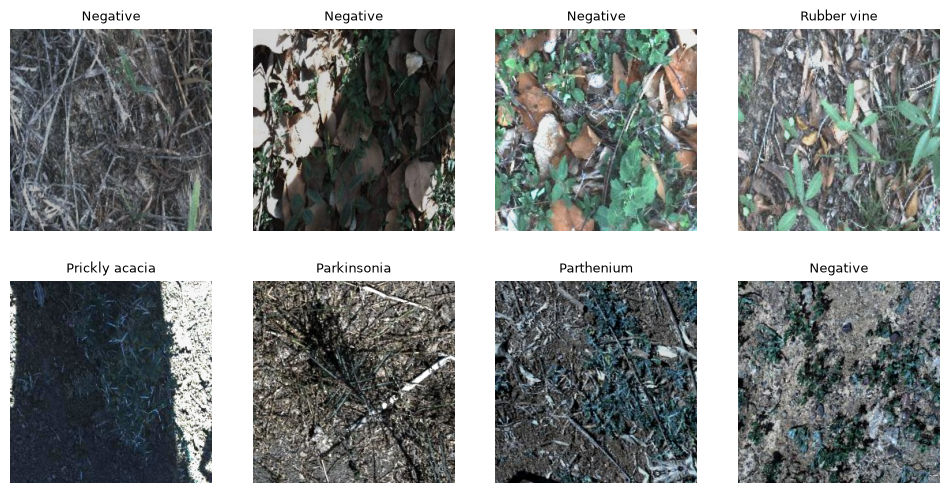

veri hattı hızı: 1988 görsel/sn


In [7]:
import os, math, time
from concurrent.futures import ThreadPoolExecutor
import torch.nn.functional as F

IMG, BS = 256, 64
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
torch.backends.cudnn.benchmark = True    
seed_all()                                  
Path("../outputs").mkdir(exist_ok=True)

tr, va, te = (df[df.split == s] for s in ["train", "val", "test"])

# ---- 1) Tüm görselleri bir kez uint8 diziye yükle (disk cache'li) ----
def load_split(d, name):
    f = Path(f"../outputs/cache_{name}_{len(d)}_{IMG}.npy")
    if f.exists():
        return np.load(f)
    paths = d.path.values
    arr = np.empty((len(d), IMG, IMG, 3), np.uint8)
    def rd(i):
        im = Image.open(paths[i]).convert("RGB")
        if im.size != (IMG, IMG): im = im.resize((IMG, IMG), Image.BILINEAR)
        arr[i] = np.asarray(im)
    with ThreadPoolExecutor(min(16, (os.cpu_count() or 4) * 2)) as ex:
        list(ex.map(rd, range(len(d))))
    np.save(f, arr); return arr

t0 = time.time()
Xtr, Xva, Xte = (torch.from_numpy(load_split(d, n)) for d, n in [(tr, "train"), (va, "val"), (te, "test")])
ytr = torch.from_numpy(tr.y.astype(np.int64).values)
yva = torch.from_numpy(va.y.astype(np.int64).values)
yte = torch.full((len(te),), -1, dtype=torch.int64)            # test etiketsiz
print(f"yüklendi: {time.time()-t0:.0f}s | train {tuple(Xtr.shape)} {Xtr.nbytes/1e9:.2f} GB")

# ---- 2) GPU augmentation (örnek başına ayrı rastgele parametre) ----
_mean = torch.tensor(MEAN, device=DEVICE).view(1, 3, 1, 1)
_std  = torch.tensor(STD,  device=DEVICE).view(1, 3, 1, 1)
def _u(B, lo, hi): return torch.empty(B, device=DEVICE).uniform_(lo, hi)

def prep_eval(xb):
    x = xb.float().div_(255)
    return ((x - _mean) / _std).contiguous(memory_format=torch.channels_last)

@torch.no_grad()
def gpu_augment(xb):
    B = xb.size(0)
    x = xb.float().div_(255)
    # geometri: RandomResizedCrop + flip + rotation tek bir affine dönüşümde
    area  = _u(B, 0.6, 1.0)
    ratio = torch.exp(_u(B, math.log(3/4), math.log(4/3)))
    sx = torch.sqrt(area * ratio).clamp(max=1.0)
    sy = torch.sqrt(area / ratio).clamp(max=1.0)
    cx = (torch.rand(B, device=DEVICE) * 2 - 1) * (1 - sx)
    cy = (torch.rand(B, device=DEVICE) * 2 - 1) * (1 - sy)
    ang = _u(B, -20, 20) * math.pi / 180
    fh = (torch.rand(B, device=DEVICE) < 0.5).float() * 2 - 1
    fv = (torch.rand(B, device=DEVICE) < 0.5).float() * 2 - 1
    cos, sin = torch.cos(ang), torch.sin(ang)
    theta = torch.stack([torch.stack([cos*sx*fh, -sin*sy*fv, cx], 1),
                         torch.stack([sin*sx*fh,  cos*sy*fv, cy], 1)], 1)       # (B,2,3)
    grid = F.affine_grid(theta, (B, 3, IMG, IMG), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)
    # renk: parlaklık / kontrast / doygunluk
    x = (x * _u(B, 0.7, 1.3).view(B, 1, 1, 1)).clamp_(0, 1)
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    x = ((x - m) * _u(B, 0.7, 1.3).view(B, 1, 1, 1) + m).clamp_(0, 1)
    g = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]
    x = ((x - g) * _u(B, 0.75, 1.25).view(B, 1, 1, 1) + g).clamp_(0, 1)
    return ((x - _mean) / _std).contiguous(memory_format=torch.channels_last)

# ---- 3) Worker'sız hızlı loader ----
class FastLoader:
    def __init__(self, X, y, bs, train):
        self.X, self.y, self.bs, self.train = X, y, bs, train
    def __len__(self):
        n = len(self.X)
        return n // self.bs if self.train else math.ceil(n / self.bs)   # train: drop_last
    def __iter__(self):
        n = len(self.X)
        idx = torch.randperm(n) if self.train else torch.arange(n)
        for i in range(len(self)):
            j = idx[i*self.bs:(i+1)*self.bs]
            xb = self.X[j].to(DEVICE, non_blocking=True).permute(0, 3, 1, 2)   # NHWC -> channels_last
            yb = self.y[j].to(DEVICE, non_blocking=True)
            yield (gpu_augment(xb) if self.train else prep_eval(xb)), yb

train_dl = FastLoader(Xtr, ytr, BS, train=True)
val_dl   = FastLoader(Xva, yva, BS, train=False)
test_dl  = FastLoader(Xte, yte, BS, train=False)

# ---- 4) Kontroller ----
xb, yb = next(iter(train_dl))
print("batch:", tuple(xb.shape), xb.dtype, f"| mean={xb.mean():.3f} std={xb.std():.3f}")

img = (xb[:8].float().cpu() * torch.tensor(STD).view(1, 3, 1, 1) + torch.tensor(MEAN).view(1, 3, 1, 1)).clamp(0, 1)
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for a, im, lab in zip(ax.flat, img, yb[:8].cpu()):
    a.imshow(im.permute(1, 2, 0)); a.set_title(CLASS_NAMES[lab], fontsize=9); a.axis("off")
plt.show()

def bench(dl, n=30):
    if DEVICE == "cuda": torch.cuda.synchronize()
    t, k = time.time(), 0
    for i, (xb, _) in enumerate(dl):
        k += len(xb)
        if i + 1 == n: break
    if DEVICE == "cuda": torch.cuda.synchronize()
    return k / (time.time() - t)
print(f"veri hattı hızı: {bench(train_dl):.0f} görsel/sn")

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import time
import timm
import numpy as np
from sklearn.metrics import f1_score

# 0. CUDNN OPTİMİZASYONU
torch.backends.cudnn.benchmark = True

# 1. SINIF AĞIRLIKLARINI HESAPLAMA (Macro-F1 için KRİTİK)
# Eğitim setindeki sınıf sayılarını alıyoruz
train_counts = df[df.split == 'train']['y'].value_counts().sort_index().values
# Scikit-learn'in 'balanced' ağırlıklandırma mantığı: N / (num_classes * count_i)
weights = len(df[df.split == 'train']) / (NUM_CLASSES * train_counts)
# Tensor'e çevirip GPU'ya atıyoruz
class_weights = torch.tensor(weights, dtype=torch.float32, device=DEVICE)

print("Sınıf Ağırlıkları (Az bulunan sınıfın cezası daha yüksek):")
for i, w in enumerate(weights):
    print(f"  {CLASS_NAMES[i]:<15}: {w:.2f}")

# 2. MODEL ve KAYIP FONKSİYONU (Loss)
model = timm.create_model('resnet18', pretrained=True, num_classes=NUM_CLASSES).to(DEVICE)

# Standart CrossEntropy yerine, ağırlıklı versiyonunu kullanıyoruz
criterion = nn.CrossEntropyLoss(weight=class_weights)

# 3. OPTIMIZER ve SCHEDULER
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4, fused=True)
epochs = 40 # Macro-F1 genelde daha geç yakınsar, epoch'u biraz artırdık
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

# 4. MIXED PRECISION (AMP)
scaler = torch.cuda.amp.GradScaler()

# 5. VERİ YÜKLEYİCİ
BS = 32 # RTX 2050 için. OOM alırsanız 16 yapın.
train_dl = FastLoader(Xtr, ytr, bs=BS, train=True, on_gpu=False, size=224)
val_dl   = FastLoader(Xva, yva, bs=BS, train=False, on_gpu=False, size=224)

# ---- EĞİTİM DÖNGÜSÜ (Macro-F1 Odaklı) ----
best_macro_f1 = 0.0

for epoch in range(1, epochs + 1):
    model.train()
    epoch_loss = 0.0
    total = 0
    
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    
    for xb, yb in train_dl:
        optimizer.zero_grad(set_to_none=True)
        
        # AMP ile İleri Yayılım
        with torch.cuda.amp.autocast(dtype=torch.float16):
            outputs = model(xb)
            # Ağırlıklı Kayıp Fonksiyonu (Weighted Loss)
            loss = criterion(outputs, yb) 
        
        # Geri Yayılım
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        epoch_loss += loss.item() * xb.size(0)
        total += yb.size(0)
        
    if DEVICE == "cuda": torch.cuda.synchronize()
    epoch_time = time.time() - t0
    scheduler.step()
    
    # ---- VALIDASYON (Macro-F1 Hesaplama) ----
    model.eval()
    all_preds = []
    all_targets = []
    val_loss = 0.0
    
    with torch.no_grad():
        for xb, yb in val_dl:
            with torch.cuda.amp.autocast(dtype=torch.float16):
                val_out = model(xb)
                val_loss += criterion(val_out, yb).item() * xb.size(0)
            
            all_preds.extend(val_out.argmax(dim=1).cpu().numpy())
            all_targets.extend(yb.cpu().numpy())
            
    # Sklearn ile gerçek Macro-F1 hesapla
    current_macro_f1 = f1_score(all_targets, all_preds, average='macro')
    val_loss_avg = val_loss / total
    
    # En iyi Macro-F1 ise modeli kaydet
    if current_macro_f1 > best_macro_f1:
        best_macro_f1 = current_macro_f1
        torch.save(model.state_dict(), "best_macro_f1_model.pth")
        
    print(f"Epoch {epoch:02d} | Süre: {epoch_time:.1f}s | "
          f"Train Loss: {epoch_loss/total:.4f} | Val Loss: {val_loss_avg:.4f} | "
          f"🎯 Val Macro-F1: {current_macro_f1:.4f} (Best: {best_macro_f1:.4f})")

print(f"\n✅ Eğitim Tamamlandı. En İyi Macro-F1 Skoru: {best_macro_f1:.4f}")

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

c:\Users\burak\Downloads\yarısma_icin_klasor\deepweeds\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\burak\.cache\huggingface\hub\models--timm--resnet18.a1_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\burak\AppData\Local\Temp\ipykernel_15104\83930093.py:42: FutureWarning: `torc

Cihaz: cuda | Hassasiyet: float16 (AMP Aktif)


W1022 17:46:13.408000 15104 Lib\site-packages\torch\_inductor\utils.py:1137] [0/0] Not enough SMs to use max_autotune_gemm mode


BackendCompilerFailed: backend='inductor' raised:
RuntimeError: Cannot find a working triton installation. Either the package is not installed or it is too old. More information on installing Triton can be found at https://github.com/openai/triton

Set TORCH_LOGS="+dynamo" and TORCHDYNAMO_VERBOSE=1 for more information


You can suppress this exception and fall back to eager by setting:
    import torch._dynamo
    torch._dynamo.config.suppress_errors = True


In [12]:
import inspect
print(inspect.signature(gpu_augment))        # (xb, size=...) görmeliyiz
print(inspect.signature(FastLoader.__init__)) # ..., on_gpu=... görmeliyiz
print(inspect.getsource(gpu_augment)[:400])   # def satırından hangi sürüm olduğu anlaşılır

(xb)
(self, X, y, bs, train)
@torch.no_grad()
def gpu_augment(xb):
    B = xb.size(0)
    x = xb.float().div_(255)
    # geometri: RandomResizedCrop + flip + rotation tek bir affine dönüşümde
    area  = _u(B, 0.6, 1.0)
    ratio = torch.exp(_u(B, math.log(3/4), math.log(4/3)))
    sx = torch.sqrt(area * ratio).clamp(max=1.0)
    sy = torch.sqrt(area / ratio).clamp(max=1.0)
    cx = (torch.rand(B, device=DEVICE) * 2 - 1) * (1


In [ ]:
h = pd.DataFrame(hist)
best = h.val_f1.idxmax()                      # en iyi epoch (kaydedilen checkpoint)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(h.ep, h.train_loss, marker="o", label="train loss")
ax[0].plot(h.ep, h.val_loss, marker="o", label="val loss")
ax[0].axvline(h.ep[best], color="gray", ls="--", label=f"en iyi epoch ({h.ep[best]})")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()

ax[1].plot(h.ep, h.val_f1, marker="o", label="val macro-F1")
ax[1].plot(h.ep, h.val_acc, marker="o", label="val accuracy")
ax[1].axvline(h.ep[best], color="gray", ls="--")
ax[1].set_title("Val metrikleri"); ax[1].set_xlabel("epoch"); ax[1].legend()

plt.tight_layout(); plt.show()

print(f"En iyi epoch: {h.ep[best]} | val macro-F1={h.val_f1[best]:.4f} | "
      f"acc={h.val_acc[best]:.4f} | val loss={h.val_loss[best]:.4f}")
print(f"Son epoch    : {h.ep.iloc[-1]} | val macro-F1={h.val_f1.iloc[-1]:.4f}")